<a href="https://colab.research.google.com/github/jerstnd/predictive_maintenance_nasa/blob/main/predictive_maintenance_nasa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Predictive Maintenance for NASA CMAPSS Turbofan Engine

This project is conducted to predict the Remaining Usable Lifetime (RUL) of the turbofan engines based on NASA CMAPSS dataset. To read a full documentation of the project, go to:



###Data Fetching

In [ ]:
import pandas as pd
import numpy as np

DATA = "/content/drive/MyDrive/cmapss/"

cols = ["unit", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"s_{i}" for i in range(1, 22)]
train = pd.read_csv(DATA + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(DATA + "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul_test = pd.read_csv(DATA + "RUL_FD001.txt", header=None, names=["RUL"])

train.head()

,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


###Data Inspection





In [ ]:
# Check data shape
print(f'Training data shape:  {train.shape}')
print(f'Testing data shape:   {test.shape}')
print(f'RUL data shape:       {rul_test.shape}')

# Check for missing value
print(f'Missing values in training data:  {train.isnull().sum().sum()}')
print(f'Missing values in testing data:   {test.isnull().sum().sum()}')
print(f'Missing values in RUL data:       {rul_test.isnull().sum().sum()}')

# Check for duplicate value
print(f'Duplicate values in training data:  {train.duplicated().sum()}')

Training data shape:  (20631, 26)
Testing data shape:   (13096, 26)
RUL data shape:       (100, 1)
Missing values in training data:  0
Missing values in testing data:   0
Missing values in RUL data:       0
Duplicate values in training data:  0


In [ ]:
# Check for Data type & memory
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   s_1        20631 non-null  float64
 6   s_2        20631 non-null  float64
 7   s_3        20631 non-null  float64
 8   s_4        20631 non-null  float64
 9   s_5        20631 non-null  float64
 10  s_6        20631 non-null  float64
 11  s_7        20631 non-null  float64
 12  s_8        20631 non-null  float64
 13  s_9        20631 non-null  float64
 14  s_10       20631 non-null  float64
 15  s_11       20631 non-null  float64
 16  s_12       20631 non-null  float64
 17  s_13       20631 non-null  float64
 18  s_14       20631 non-null  float64
 19  s_15       20631 non-null  float64
 20  s_16  

In [ ]:
# Check for statistical summary
train.describe().T

,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
s_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


In [ ]:
# Check if cycles start at 1 and be consecutive per engine
ok = train.groupby('unit')['cycle'].apply(lambda c: (c.diff().dropna() == 1).all() and c.iloc[0] == 1)
print(f'all engines have consecutive cycles from 1: {ok.all()}')

# Check if last cycle per engine, and the RUL file have one row per test engine
print(test.groupby('unit')['cycle'].max().describe())
print(f'last cycle per engine and RUL file have one row per test engine: {len(rul_test) == test['unit'].nunique()}')


all engines have consecutive cycles from 1: True
count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: cycle, dtype: float64
last cycle per engine and RUL file have one row per test engine: True


###Data Cleaning & Feature Engineering

In [ ]:
sensor_cols = [c for c in train.columns if c.startswith('s_')]
setting_cols = [c for c in train.columns if c.startswith('setting_')]

stats = train[setting_cols + sensor_cols].agg(['std', 'nunique']).T
print(stats)

# constant or near-constant columns carry no information
const_cols = stats[stats['std'] < 1e-6].index.tolist()
print(f'constant columns: {len(const_cols)}')

                    std  nunique
setting_1  2.187313e-03    158.0
setting_2  2.930621e-04     13.0
setting_3  0.000000e+00      1.0
s_1        6.537152e-11      1.0
s_2        5.000533e-01    310.0
s_3        6.131150e+00   3012.0
s_4        9.000605e+00   4051.0
s_5        3.394700e-12      1.0
s_6        1.388985e-03      2.0
s_7        8.850923e-01    513.0
s_8        7.098548e-02     53.0
s_9        2.208288e+01   6403.0
s_10       4.660829e-13      1.0
s_11       2.670874e-01    159.0
s_12       7.375534e-01    427.0
s_13       7.191892e-02     56.0
s_14       1.907618e+01   6078.0
s_15       3.750504e-02   1918.0
s_16       1.556432e-14      1.0
s_17       1.548763e+00     13.0
s_18       0.000000e+00      1.0
s_19       0.000000e+00      1.0
s_20       1.807464e-01    120.0
s_21       1.082509e-01   4745.0
constant columns: 7


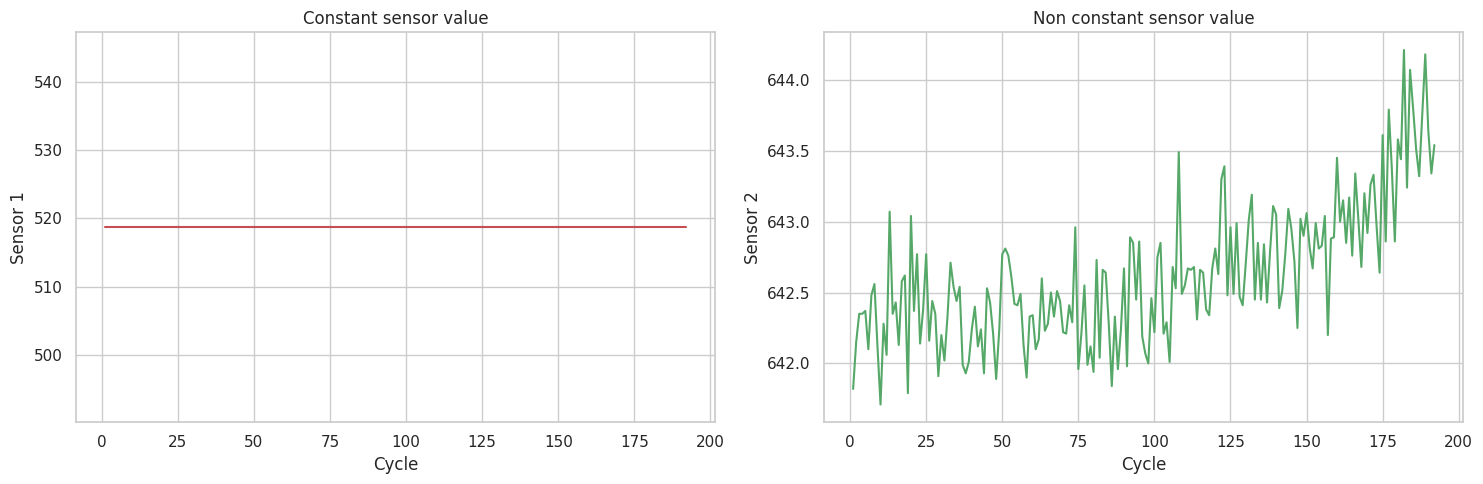

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(15,5))

sns.lineplot(x='cycle', y='s_1', data=train[train['unit'] == 1], ax=ax[0], color='r')
sns.lineplot(x='cycle', y='s_2', data=train[train['unit'] == 1], ax=ax[1], color='g')
ax[0].set_title('Constant sensor value')
ax[1].set_title('Non constant sensor value')
ax[0].set(xlabel="Cycle", ylabel="Sensor 1")
ax[1].set(xlabel="Cycle", ylabel="Sensor 2")

plt.tight_layout()
plt.show()

In [ ]:
# Drop constant columns
train_clean = train.drop(columns=const_cols)
test_clean = test.drop(columns=const_cols)

feature_cols = [c for c in train_clean.columns if c not in ("unit", "cycle")]
print(len(feature_cols), "features kept")

17 features kept


In [ ]:
# Apply RUL cap & label
CLIP = 125
train_clean["RUL"] = (train_clean.groupby("unit")["cycle"].transform("max")
                      - train_clean["cycle"]).clip(upper=CLIP)

base_cols = [c for c in train_clean.columns if c.startswith('s_')]
print(len(base_cols), base_cols)

15 ['s_2', 's_3', 's_4', 's_6', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']


In [ ]:
# Rolling feature per engine
def add_features(df, base, windows=(5, 10, 30)):
    df = df.sort_values(['unit', 'cycle']).reset_index(drop=True)
    g = df.groupby('unit')[base]
    parts = [df]
    for w in windows:
        mean = (g.rolling(w, min_periods=1).mean()
                 .reset_index(level=0, drop=True).add_suffix(f'_mean{w}'))
        std = (g.rolling(w, min_periods=2).std()
                .reset_index(level=0, drop=True).fillna(0).add_suffix(f'_std{w}'))
        trend = (g.diff(w - 1) / (w - 1)).fillna(0).add_suffix(f'_trend{w}')
        parts += [mean, std, trend]
    return pd.concat(parts, axis=1)

train_f = add_features(train_clean, base_cols)
test_f = add_features(test_clean, base_cols)

features = [c for c in train_f.columns
            if c not in ('unit', 'RUL') and c != 'cycle'] + ['cycle']
X, y, groups = train_f[features], train_f['RUL'], train_f['unit']
print(X.shape)

(20631, 153)


###Modelling & Evaluation

In [ ]:
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, r2_score

def rmse(a, b):
  return np.sqrt(mean_squared_error(a,b))

def make_xgb(**overrides):
  params = dict(n_estimators=500, learning_rate=0.03, max_depth=5,
                min_child_weight=50, subsample=0.8, colsample_bytree=0.7,
                reg_lambda=1.0, random_state=42, n_jobs=-1)
  params.update(overrides)
  return xgb.XGBRegressor(**params)

gkf = GroupKFold(n_splits=5)

def cv_metrics(make_model, X, y, groups):
    rows = []
    for tr, va in gkf.split(X, y, groups):
        m = make_model().fit(X.iloc[tr], y.iloc[tr])
        p = np.clip(m.predict(X.iloc[va]), 0, CLIP)
        rows.append({"RMSE": rmse(y.iloc[va], p), "R2": r2_score(y.iloc[va], p)})
    df = pd.DataFrame(rows)
    return df.mean().round(3), df.std().round(3)

mean, std = cv_metrics(make_xgb, X, y, groups)
print("CV mean:\n", mean, "\nCV std:\n", std)


CV mean:
 RMSE    13.465
R2       0.895
dtype: float64 
CV std:
 RMSE    0.779
R2      0.012
dtype: float64


In [ ]:
def nasa_score(true, pred):
    d = pred - true
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

model = make_xgb().fit(X, y)

last = test_f.sort_values(["unit", "cycle"]).groupby("unit").tail(1)
pred_last = np.clip(model.predict(last[features]), 0, None)
y_true = rul_test["RUL"].values

print("rows:", len(last))   # must be 100

def evaluate(true, pred, label=""):
    return {
        "set": label,
        "RMSE": rmse(true, pred),
        "R2": r2_score(true, pred),
        "NASA score": nasa_score(true, pred),
    }

results = pd.DataFrame([
    evaluate(y_true, pred_last, "last cycle, raw truth"),
    evaluate(np.minimum(y_true, CLIP), pred_last, "last cycle, clipped truth"),
]).round(3)
print(results.to_string(index=False))

rows: 100
                      set   RMSE    R2  NASA score
    last cycle, raw truth 15.498 0.861     376.073
last cycle, clipped truth 14.160 0.875     329.783


####Model's Performance

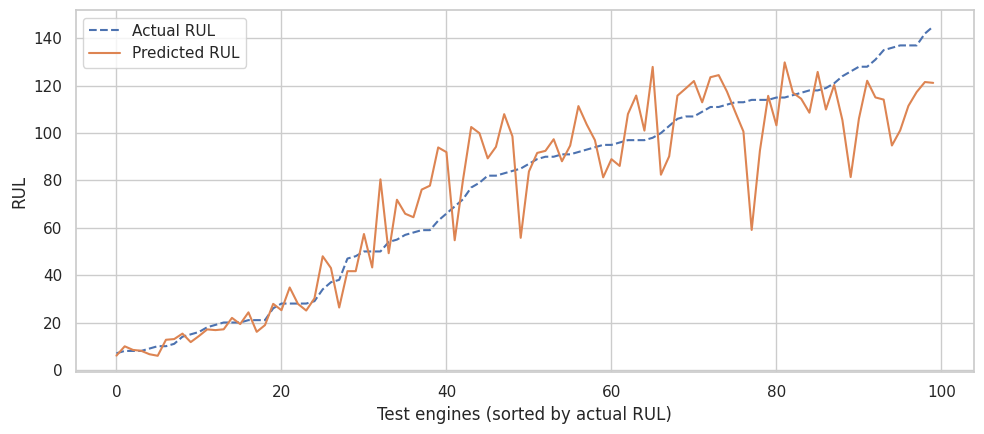

In [ ]:
s = final.sort_values("actual").reset_index(drop=True)
plt.figure(figsize=(10, 4.5))
sns.lineplot(x=s.index, y=s["actual"], linestyle="--", label="Actual RUL")
sns.lineplot(x=s.index, y=s["predicted"], label="Predicted RUL")
plt.xlabel("Test engines (sorted by actual RUL)"); plt.ylabel("RUL")
plt.tight_layout(); plt.show()

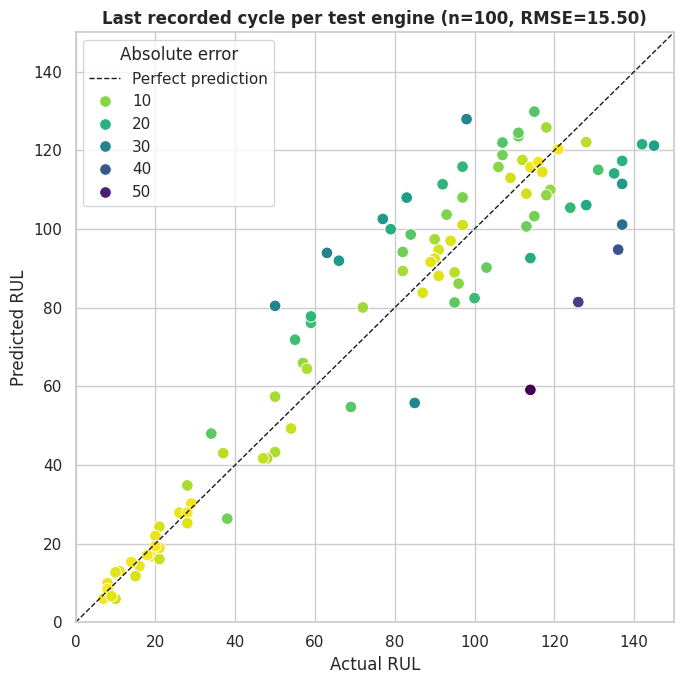

In [ ]:
final = pd.DataFrame({
    "unit": last["unit"].values,
    "actual": y_true,
    "predicted": pred_last,
})
final["abs_error"] = (final["predicted"] - final["actual"]).abs()
score = rmse(final["actual"], final["predicted"])

plt.figure(figsize=(7, 7))
lim = max(final["actual"].max(), final["predicted"].max()) + 5
plt.plot([0, lim], [0, lim], "k--", lw=1, label="Perfect prediction")
sns.scatterplot(data=final, x="actual", y="predicted", hue="abs_error",
                palette="viridis_r", s=70, edgecolor="white")
plt.xlim(0, lim); plt.ylim(0, lim)
plt.title(f"Last recorded cycle per test engine (n=100, RMSE={score:.2f})",
          fontweight="bold")
plt.xlabel("Actual RUL"); plt.ylabel("Predicted RUL")
plt.legend(title="Absolute error", loc="upper left")
plt.tight_layout()
plt.savefig("final_cycle_scatter.png", dpi=150)
plt.show()

####Feature Relevance

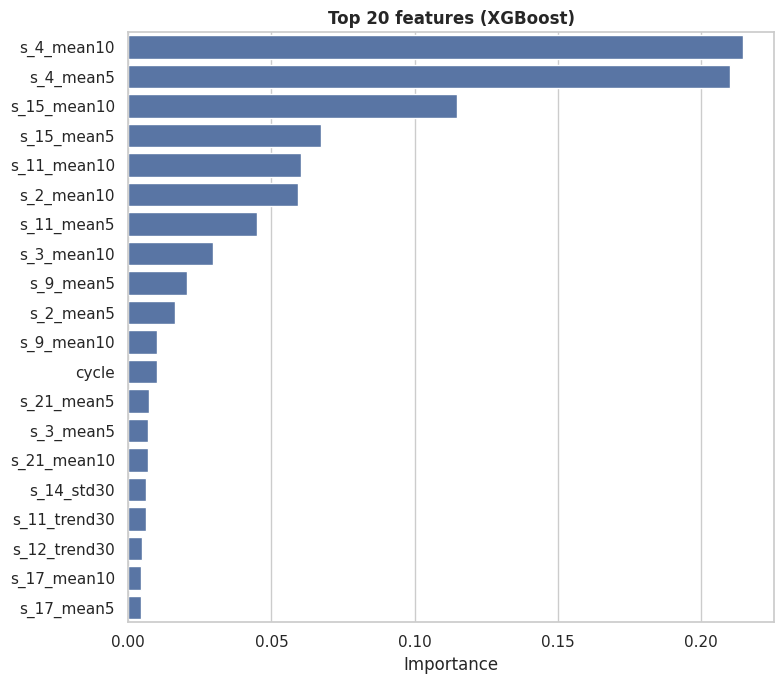

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")

top = imp.head(20).reset_index()
top.columns = ["feature", "importance"]

plt.figure(figsize=(8, 7))
sns.barplot(data=top, x="importance", y="feature", color="#4C72B0")
plt.title("Top 20 features (XGBoost)", fontweight="bold")
plt.xlabel("Importance"); plt.ylabel("")
plt.tight_layout()
plt.savefig("top20_features.png", dpi=150)
plt.show()

####Model Simulation

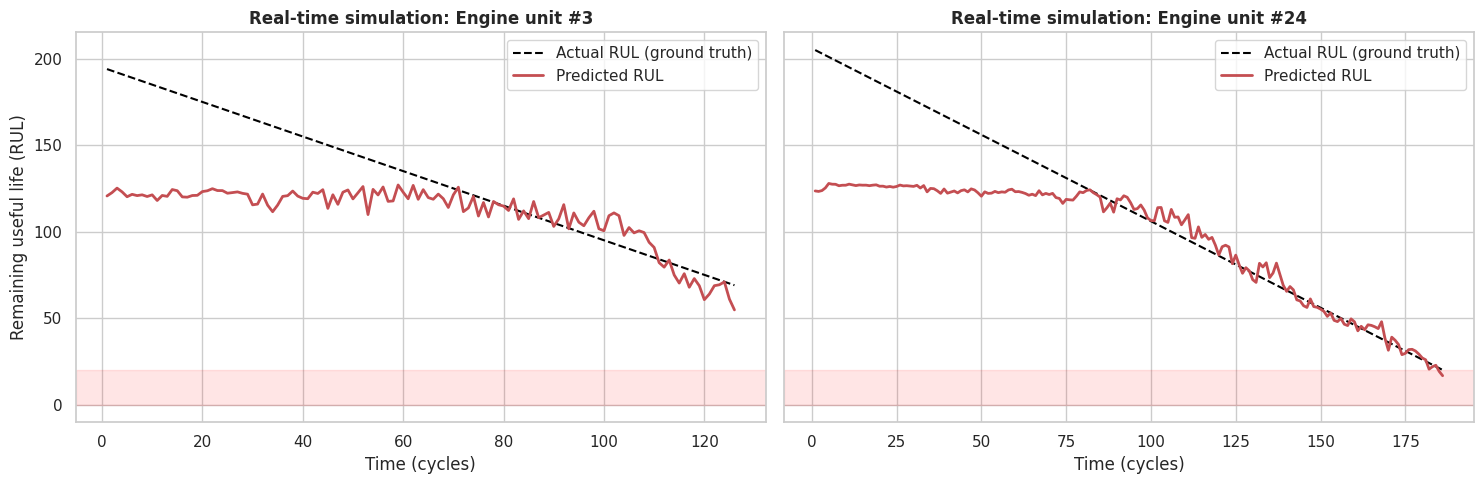

In [ ]:
units = [3, 24]
threshold = 20
CLIP = 125

fig, axes = plt.subplots(1, len(units), figsize=(15, 5), sharey=True)

for ax, u in zip(axes, units):
    d = test_f[test_f["unit"] == u].sort_values("cycle").copy()
    d["true_plot"] = d["true_RUL"].clip(upper=CLIP)

    sns.lineplot(data=d, x="cycle", y="true_RUL", color="black",
                 linestyle="--", label="Actual RUL (ground truth)", ax=ax)
    sns.lineplot(data=d, x="cycle", y="pred_RUL", color="#C44E52",
                 linewidth=2, label="Predicted RUL", ax=ax)
    ax.axhspan(0, threshold, color="red", alpha=0.1)
    ax.set_title(f"Real-time simulation: Engine unit #{u}", fontweight="bold")
    ax.set_xlabel("Time (cycles)")
    ax.set_ylabel("Remaining useful life (RUL)")
    ax.legend()

plt.tight_layout()
plt.show()